# Render a pixel batch

Render a Cornell box and a rectangular pixel batch with the same seed. Verify that batch pixels match the corresponding full-image pixels.

Use the environment described in [README](README.md). Run all cells in order.
Defaults use modest resolution/sample counts for interactive GPU execution; increase them for smoother estimates.


In [1]:
import psdr_jit as psdr
import drjit
from drjit.cuda.ad import Float as FloatD, Matrix4f as Matrix4fD
from drjit.cuda import Int as IntC, Matrix4f as Matrix4fC
import numpy as np
import matplotlib.pyplot as plt
from image_util import DATA_DIR, to_image, to_srgb

assert drjit.has_backend(drjit.JitBackend.CUDA), "An NVIDIA GPU/driver is required."
# Keep bounds and other JIT checks active while learning/debugging.
drjit.set_flag(drjit.JitFlag.Debug, True)
SEED = 42

jitc_llvm_init(): LLVM API initialization failed ..


In [2]:
sc = psdr.Scene()
sc.opts.log_level = 0
sc.opts.spp = 16
sc.opts.sppe = 0
sc.opts.sppse = 0 
sc.opts.height = 120 
sc.opts.width = 160

integrator = psdr.PathTracer(2)

In [3]:
sensor = psdr.PerspectiveCamera(60, 0.000001, 10000000.)
to_world = Matrix4fD([[1.,0.,0.,278.],
                     [0.,1.,0.,273.],
                     [0.,0.,1.,-500.],
                     [0.,0.,0.,1.],])
sensor.to_world = to_world
sc.add_Sensor(sensor)

In [4]:
alpha = psdr.Bitmap1fD(0.01)
eta = psdr.Bitmap3fD( [0.155475, 0.116753, 0.138334])
k = psdr.Bitmap3fD( [4.83181, 3.12296, 2.1486])

mybsdf1 = psdr.RoughConductorBSDF(alpha, eta, k)
sc.add_BSDF(mybsdf1, "sphere_large")


mybsdf2 = psdr.DiffuseBSDF([0.5, 0.5, 0.5])
sc.add_BSDF(mybsdf2, "back")

mybsdf3 = psdr.DiffuseBSDF([0.5, 0.5, 0.5])
sc.add_BSDF(mybsdf3, "light")

mybsdf4 = psdr.DiffuseBSDF([0.9, 0.6, 0.1])
sc.add_BSDF(mybsdf4, "sphere_small")

mybsdf5 = psdr.DiffuseBSDF([0.95, 0.95, 0.95])
sc.add_BSDF(mybsdf5, "white")

mybsdf6 = psdr.DiffuseBSDF([0.2, 0.9, 0.2])
sc.add_BSDF(mybsdf6, "green")

mybsdf7 = psdr.DiffuseBSDF([0.9, 0.2, 0.2])
sc.add_BSDF(mybsdf7, "red")

In [5]:
sc.add_Mesh(str(DATA_DIR / "cbox/cbox_luminaire.obj"), Matrix4fC([[1.,0.,0.,0.],[0.,1.,0.,-0.5],[0.,0.,1.,0.],[0.,0.,0.,1.]]), "light", psdr.AreaLight([20.0, 20.0, 8.0]))
sc.add_Mesh(str(DATA_DIR / "cbox/cbox_smallball.obj"), Matrix4fC([[1.,0.,0.,0.],[0.,1.,0.,0.],[0.,0.,1.,0.],[0.,0.,0.,1.]]), "sphere_small", None)
sc.add_Mesh(str(DATA_DIR / "cbox/cbox_largeball.obj"), Matrix4fC([[1.,0.,0.,0.],[0.,1.,0.,0.],[0.,0.,1.,0],[0.,0.,0.,1.]]), "sphere_large", None)
sc.add_Mesh(str(DATA_DIR / "cbox/cbox_floor.obj"), Matrix4fC([[1.,0.,0.,0.],[0.,1.,0.,0.],[0.,0.,1.,0.],[0.,0.,0.,1.]]), "white", None)
sc.add_Mesh(str(DATA_DIR / "cbox/cbox_ceiling.obj"), Matrix4fC([[1.,0.,0.,0.],[0.,1.,0.,0.],[0.,0.,1.,0.],[0.,0.,0.,1.]]), "white", None)
sc.add_Mesh(str(DATA_DIR / "cbox/cbox_back.obj"), Matrix4fC([[1.,0.,0.,0.],[0.,1.,0.,0.],[0.,0.,1.,0.],[0.,0.,0.,1.]]), "back", None)
sc.add_Mesh(str(DATA_DIR / "cbox/cbox_greenwall.obj"), Matrix4fC([[1.,0.,0.,0.],[0.,1.,0.,0.],[0.,0.,1.,0.],[0.,0.,0.,1.]]), "green", None)
sc.add_Mesh(str(DATA_DIR / "cbox/cbox_redwall.obj"), Matrix4fC([[1.,0.,0.,0.],[0.,1.,0.,0.],[0.,0.,1.,0.],[0.,0.,0.,1.]]), "red", None)

with drjit.suspend_grad():
    sc.configure()

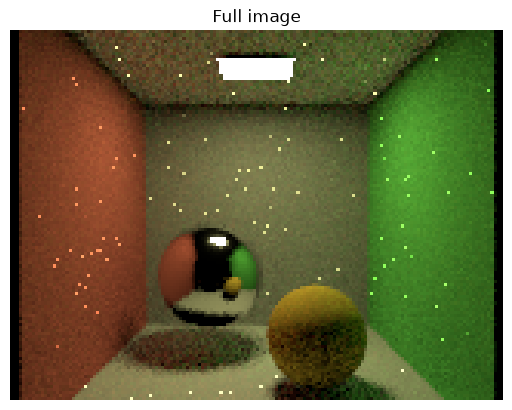

In [6]:
full = integrator.renderC(sc, 0, seed=SEED)
full_image = to_image(full, sc.opts.height, sc.opts.width)
assert np.isfinite(full_image).all() and full_image.mean() > 0
plt.imshow(to_srgb(full_image))
plt.title("Full image")
plt.axis("off");

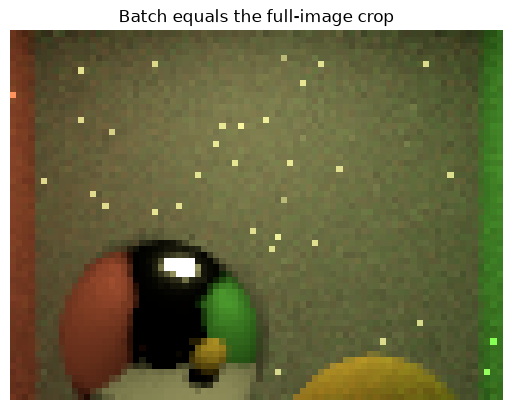

In [7]:
# Pixel indices are row-major; Dr.Jit RGB arrays are channel-first.
y0, y1 = sc.opts.height // 4, 3 * sc.opts.height // 4
x0, x1 = sc.opts.width // 4, 3 * sc.opts.width // 4
pixel_grid = np.arange(sc.opts.height * sc.opts.width, dtype=np.int32).reshape(sc.opts.height, sc.opts.width)
pixel_ids = IntC(pixel_grid[y0:y1, x0:x1].ravel())
batch = integrator.renderC(sc, 0, seed=SEED, batch_pix=pixel_ids)
batch_image = to_image(batch, y1 - y0, x1 - x0)
np.testing.assert_allclose(batch_image, full_image[y0:y1, x0:x1], rtol=1e-3, atol=2e-5)
plt.imshow(to_srgb(batch_image))
plt.title("Batch equals the full-image crop")
plt.axis("off");